# Simulación de Montecarlo para el retiro


### 1. librerias y explicacion

En México, el ahorro para el retiro se invierte en una **AFORE**, que a su vez lo invierte en fondos llamados **SIEFORE**. Nadie sabe cuánto van a rendir en los próximos 43 años, pero sí se sabe cuánto rindieron cada mes desde el 2000. La idea es:

1. Calcular el **rendimiento real de cada mes** de la SIEFORE, ya descontada la inflación.
2. Para simular un futuro, a cada uno de los 516 meses (43 años × 12) se le asigna **un mes de la historia sorteado al azar**.
3. Repetir esto **1,000 veces**, para tener 1,000 futuros posibles.
4. Ver cuánto dinero hay al final de cada futuro.

A este método se le llama **bootstrap**: se sortea de los datos reales, sin suponer ninguna distribución.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Datos

Se usan tres archivos de datos públicos:

- 01_precios_bolsa_siefores.csv
- inpc-mexico-serie-mensual-calcu-mx.csv
- 10_rendimientos_precio_bolsa.csv


In [39]:
# Cargar los precios de las SIEFORE
# cada renglon es: fecha, afore, siefore y el precio de ese dia
RUTA = 'data/'                      # carpeta donde estan los 3 csv
precios = pd.read_csv(RUTA + '01_precios_bolsa_siefores.csv', parse_dates=['fecha'])

print(f'Forma del dataset: {precios.shape}')
print(f'Columnas: {precios.columns.tolist()}')
print(f'AFOREs: {precios["afore"].nunique()} | SIEFOREs: {precios["siefore"].nunique()}')
precios.head(3)

Forma del dataset: (648469, 4)
Columnas: ['fecha', 'afore', 'siefore', 'precio']
AFOREs: 11 | SIEFOREs: 25


,fecha,afore,siefore,precio
0,2003-03-17,azteca,sb 1000,1.009736
1,2003-03-18,azteca,sb 1000,1.009986
2,2003-03-19,azteca,sb 1000,1.010371


In [40]:
# Revisar nulos y tipos de datos
print('Nulos por columna:')
print(precios.isnull().sum())
print()
print('Tipos de datos:')
print(precios.dtypes) 

Nulos por columna:
fecha      0
afore      0
siefore    0
precio     0
dtype: int64

Tipos de datos:
fecha      datetime64[us]
afore                 str
siefore               str
precio            float64
dtype: object


In [41]:
# Quedarnos solo con la SIEFORE que nos interesa
# el archivo trae todas las siefores de todas las afores, solo usamos la sb 1000 (Basica Inicial)
SIEFORE = 'sb 1000'

filas_antes = len(precios)
precios = precios[precios['siefore'] == SIEFORE]

print(f'Filas antes: {filas_antes:,} | Filas despues: {len(precios):,}')
print(f'Fechas: de {precios["fecha"].min().date()} a {precios["fecha"].max().date()}')

Filas antes: 648,469 | Filas despues: 63,772
Fechas: de 1997-07-02 a 2025-12-31


In [42]:
precios = precios.drop(columns=['siefore'])
print(f'Columnas que quedan: {precios.columns.tolist()}')

Columnas que quedan: ['fecha', 'afore', 'precio']


In [43]:
# Acomodar la tabla: un renglon por fecha y una columna por afore
precios_ancho = precios.pivot_table(index='fecha', columns='afore', values='precio')

print(f'Forma despues del pivot: {precios_ancho.shape} ({precios_ancho.shape[0]:,} dias x {precios_ancho.shape[1]} afores)')
precios_ancho.tail(3)

Forma despues del pivot: (7175, 10) (7,175 dias x 10 afores)


afore,azteca,banamex,coppel,inbursa,invercap,pensionissste,principal,profuturo,sura,xxi-banorte
fecha,,,,,,,,,,
2025-12-29,4.957716,17.865387,3.854076,11.799393,4.443786,3.652804,15.268063,20.357088,20.540323,17.269826
2025-12-30,4.952938,17.848882,3.851266,11.792930,4.436320,3.651056,15.230174,20.315314,20.506280,17.232582
2025-12-31,4.962836,17.879151,3.856520,11.807819,4.442581,3.655101,15.264329,20.331195,20.556511,17.258048


In [44]:
# Pasar de precios diarios a mensuales
# resample('ME') agrupa por mes y .last() toma el ultimo precio de cada mes
precio_mensual = precios_ancho.resample('ME').last()
print(f'Dias: {len(precios_ancho):,} -> Meses: {len(precio_mensual)}')

# los nulos son los meses en los que esa afore todavia no existia
print('\nMeses sin dato por afore:')
print(precio_mensual.isnull().sum())

Dias: 7,175 -> Meses: 342

Meses sin dato por afore:
afore
azteca            68
banamex            0
coppel           105
inbursa            0
invercap          91
pensionissste    114
principal          0
profuturo          0
sura               0
xxi-banorte        0
dtype: int64


In [45]:
# Cargar el INPC (sirve para medir la inflacion)
# las lineas que empiezan con # son notas del archivo, se ignoran con comment='#'
inpc = pd.read_csv(RUTA + 'inpc-mexico-serie-mensual-calcu-mx.csv', comment='#')

print(f'Forma del dataset: {inpc.shape}')
print(f'Columnas: {inpc.columns.tolist()}')
inpc.head(3)

Forma del dataset: (441, 7)
Columnas: ['mes', 'anio', 'numero_mes', 'inpc', 'variacion_mensual_pct', 'variacion_anual_pct', 'acumulada_anio_pct']


,mes,anio,numero_mes,inpc,variacion_mensual_pct,variacion_anual_pct,acumulada_anio_pct
0,1990-01,1990,1,7.776037,NaN,NaN,NaN
1,1990-02,1990,2,7.952120,2.2644,NaN,NaN
2,1990-03,1990,3,8.092310,1.7629,NaN,NaN


In [46]:
# Eliminar las columnas que no usamos
# solo necesitamos el mes y el indice, la inflacion la calculamos nosotros con el indice
columnas_a_eliminar = ['anio', 'numero_mes', 'variacion_mensual_pct', 'variacion_anual_pct', 'acumulada_anio_pct']
inpc = inpc.drop(columns=columnas_a_eliminar)

print(f'Columnas que quedan: {inpc.columns.tolist()}')

Columnas que quedan: ['mes', 'inpc']


In [47]:
# Convertir 'mes' de texto a fecha y ponerla como indice
# se pone al fin de mes para que coincida con las fechas de precio_mensual
print(f'Tipo de mes antes: {inpc["mes"].dtype}')

inpc['mes'] = pd.to_datetime(inpc['mes']) + pd.offsets.MonthEnd(0)
inpc = inpc.set_index('mes')

print(f'Tipo del indice despues: {inpc.index.dtype}')
inpc.head(3)

Tipo de mes antes: str
Tipo del indice despues: datetime64[us]


,inpc
mes,
1990-01-31,7.776037
1990-02-28,7.952120
1990-03-31,8.092310


## 3. Rendimiento real de cada mes

1. **De días a meses:** se toma el último precio de cada mes, para cada AFORE.
2. **Rendimiento nominal del mes:** $r = \frac{P_{\text{mes}}}{P_{\text{mes anterior}}} - 1$. Se calcula para cada AFORE y se promedian todas, para representar al **sistema completo** y no a una AFORE en particular.
3. **Inflación del mes:** $\pi = \frac{INPC_{\text{mes}}}{INPC_{\text{mes anterior}}} - 1$.
4. **Rendimiento real:** lo que creció el **poder de compra**:
$$r_{\text{real}} = \frac{1 + r}{1 + \pi} - 1$$

Al usar rendimientos reales, todos los resultados quedan directamente en **pesos de hoy**.

In [48]:
# Rendimiento nominal de cada mes, para cada afore
# pct_change() = precio_mes / precio_mes_anterior - 1  (cuanto subio o bajo en %)
# fill_method=None para que no rellene los meses donde la afore no existia
rend_por_afore = precio_mensual.pct_change(fill_method=None)
rend_por_afore.tail(3)

afore,azteca,banamex,coppel,inbursa,invercap,pensionissste,principal,profuturo,sura,xxi-banorte
fecha,,,,,,,,,,
2025-10-31,0.015549,0.019243,0.015509,0.014056,0.018809,0.011796,0.021031,0.023222,0.017213,0.022244
2025-11-30,0.001157,0.002047,0.005240,0.006180,0.001395,0.004240,0.003311,0.000302,0.006526,0.003933
2025-12-31,0.003846,0.002097,0.001941,0.008323,0.005586,0.002934,0.003185,0.004509,0.002148,0.005817


In [49]:
#Promedio de todas las afores para representar al sistema completo
# axis=1 = promedio por renglon (de todas las afores en ese mes)
rend_nominal = rend_por_afore.mean(axis=1)
print(rend_nominal.tail(3))

fecha
2025-10-31    0.017867
2025-11-30    0.003433
2025-12-31    0.004039
Freq: ME, dtype: float64


In [50]:
#Inflacion de cada mes: INPC_mes / INPC_mes_anterior - 1
inflacion = inpc['inpc'].pct_change()
print(inflacion.tail(3))

mes
2026-07-31    0.000262
2026-08-31    0.002018
2026-09-30    0.004214
Name: inpc, dtype: float64


In [51]:
# Juntamos rendimiento e inflacion en un solo Df
df = pd.DataFrame({'rend_nominal': rend_nominal, 'inflacion': inflacion})

print(f'Forma: {df.shape}')
print('\nNulos por columna:')
print(df.isnull().sum())

Forma: (441, 2)

Nulos por columna:
rend_nominal    100
inflacion         1
dtype: int64


In [52]:
# Limpiamos al eiminar los meses donde falta alguno de los dos datos
filas_antes = len(df)
df = df.dropna()

# nos quedamos con los datos desde el 2000 para hacerlo mas actual
ANIO_INICIO = 2000

filas_antes = len(df)
df = df[df.index.year >= ANIO_INICIO]

print(f'Filas antes: {filas_antes} | Filas despues: {len(df)}')
print(f'Meses de datos: de {df.index[0]:%Y-%m} a {df.index[-1]:%Y-%m}')

Filas antes: 341 | Filas despues: 312
Meses de datos: de 2000-01 a 2025-12


In [53]:
# Rendimiento real = lo que crecio el poder de compra quitando la inflacion
df['rend_real'] = (1 + df['rend_nominal']) / (1 + df['inflacion']) - 1
df.head()

,rend_nominal,inflacion,rend_real
2000-01-31,0.016229,0.013427,0.002764
2000-02-29,0.018022,0.008870,0.009071
2000-03-31,0.015802,0.005544,0.010201
2000-04-30,0.009905,0.005690,0.004191
2000-05-31,-0.002463,0.003738,-0.006179


### Verificación contra los datos oficiales de CONSAR

Antes de simular hay que comprobar que los cálculos están bien. Se calcula el rendimiento nominal de los últimos 12 meses y se compara con el que publica CONSAR para la misma SIEFORE.

In [54]:
# Rendimientos oficiales a 12 meses de CONSAR
consar = pd.read_csv(RUTA + '10_rendimientos_precio_bolsa.csv', parse_dates=['fecha'])

#se filtra el promedio ponderado de la misma siefore y el plazo de 12 meses
nombre = f'{SIEFORE} promedio ponderado'
consar = consar[(consar['tipo_recurso'] == nombre) & (consar['afore'] == nombre) & (consar['plazo'] == '12 meses')]

consar = consar.set_index('fecha')['monto']             # solo el rendimiento, con la fecha como indice
consar.index = consar.index + pd.offsets.MonthEnd(0)    # fecha a fin de mes para comparar
print(f'Meses de datos de CONSAR: {len(consar)}')

Meses de datos de CONSAR: 73


In [55]:
#Nuestro rendimiento a 12 meses
# rolling(12) toma ventanas de 12 meses seguidos y np.prod multiplica los (1 + r)
# se multiplican en vez de sumar porque los rendimientos se acumulan (interes compuesto)
nuestro = ((1 + rend_nominal).rolling(12).apply(np.prod, raw=True) - 1) * 100

# se juntan las dos y se comparan cada diciembre
comparacion = pd.DataFrame({'CONSAR (%)': consar, 'Calculado (%)': nuestro}).dropna()
print('Rendimiento nominal a 12 meses, cada diciembre:')
print(comparacion[comparacion.index.month == 12].round(2))

# si la diferencia es chica y la correlacion es cercana a 1, los calculos deberian etar bien
print(f'\nDiferencia promedio: {(comparacion["CONSAR (%)"] - comparacion["Calculado (%)"]).abs().mean():.2f} puntos')
print(f'Correlacion: {comparacion.corr().iloc[0, 1]:.3f}')

Rendimiento nominal a 12 meses, cada diciembre:
            CONSAR (%)  Calculado (%)
fecha                                
2019-12-31       14.89          14.41
2020-12-31       12.91          12.92
2021-12-31        7.14           8.42
2022-12-31       -6.03          -5.41
2023-12-31        8.97           9.25
2024-12-31        8.63           8.93
2025-12-31       17.42          17.45

Diferencia promedio: 0.50 puntos
Correlacion: 0.999


In [56]:
# Datos que se van a sortear: los rendimientos reales mensuales
rendimientos = df['rend_real'].values

# rendimiento real de cada año: se multiplican los (1 + r) de los meses de ese año
anual_real = (1 + df['rend_real']).groupby(df.index.year).prod() - 1

# promedio anual: se multiplican todos los meses y se convierte a un año con ** (12 / meses)
print(f'Meses que se van a sortear: {len(rendimientos)}')
print(f'Rendimiento real promedio:  {(1 + rendimientos).prod() ** (12 / len(rendimientos)) - 1:.1%} anual')
print(f'Meses con perdida real:     {np.mean(rendimientos < 0):.0%}')     # promedio de True/False = % de True
print(f'Peor año: {anual_real.idxmin()} ({anual_real.min():.1%}) | Mejor año: {anual_real.idxmax()} ({anual_real.max():.1%})')

Meses que se van a sortear: 312
Rendimiento real promedio:  3.9% anual
Meses con perdida real:     32%
Peor año: 2022 (-12.3%) | Mejor año: 2025 (13.3%)


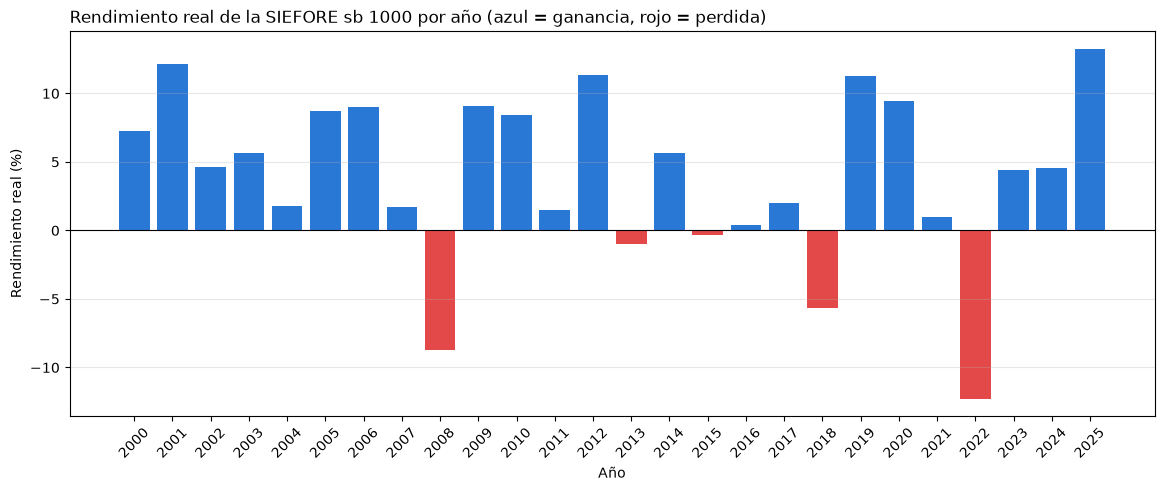

In [57]:
# Graficamos el rendimiento real de cada año
colores = ['#2a78d6' if r >= 0 else '#e34948' for r in anual_real]

plt.figure(figsize=(14, 5))
plt.bar(anual_real.index, anual_real * 100, color=colores, width=0.8)   # * 100 para verlo en %
plt.axhline(0, color='black', linewidth=0.8)                            # linea en 0
plt.xticks(anual_real.index, rotation=45)                               # que se vean todos los años
plt.title(f'Rendimiento real de la SIEFORE {SIEFORE} por año (azul = ganancia, rojo = perdida)', loc='left')
plt.ylabel('Rendimiento real (%)')
plt.xlabel('Año')
plt.grid(axis='y', alpha=0.3)
plt.show()

### 4. Parámetros del retiro

| Parámetro | Valor |
|:---|:---|
| Edad actual / de retiro | 22 / 65 años (43 años = 516 meses) |
| Ahorro inicial | 10,000 pesos |
| Aportación | 2,000 pesos al mes, en pesos de hoy |
| Meta | 3,000,000 pesos de hoy (para retirar 10,000 pesos al mes con la regla del 4%: 10,000 × 12 / 0.04) |
| Simulaciones | 1,000 futuros |

In [58]:
EDAD_ACTUAL = 22
EDAD_RETIRO = 65
meses = (EDAD_RETIRO - EDAD_ACTUAL) * 12    # 43 años x 12 = 516 meses de inversion
trials = 1_000                              # numero de futuros simulados

AHORRO_INICIAL = 10_000                     # pesos al abrir la cuenta
APORTACION_MENSUAL = 2_000                  # pesos al mes (en pesos de hoy, o sea que sube con la inflacion)

# meta: para retirar 10,000 al mes (120,000 al año) con la regla del 4% se necesita 120,000 / 0.04
META = 10_000 * 12 / 0.04

print(f'Meses de inversion: {meses} | Simulaciones: {trials:,} | Meta: ${META:,.0f}')

Meses de inversion: 516 | Simulaciones: 1,000 | Meta: $3,000,000


### 5. Simulación de Montecarlo

In [59]:
#Matiz de resultados: filas = meses (0 a 516), columnas = futuros
# se llena de ceros y se va rellenando con el saldo de cada mes
Simulaciones = np.zeros((meses + 1, trials))
rng = np.random.default_rng(SEED)           # generador de numeros aleatorios con la semilla para reproducibilidad

for i in range(trials):                               # cada trial (un futuro posible)
    saldo = AHORRO_INICIAL                            # todos los futuros empiezan con el ahorro inicial
    Simulaciones[0, i] = saldo                        # mes 0
    for t in range(meses):                            # cada mes de ese futuro
        # se sortea un mes real de la historia; puede repetirse, como sacar una pelota y regresarla
        r = rng.choice(rendimientos)
        # el saldo crece (o baja) con ese rendimiento y al final del mes se deposita la aportacion
        saldo = saldo * (1 + r) + APORTACION_MENSUAL
        Simulaciones[t + 1, i] = saldo                # se guarda el saldo de ese mes

finales = Simulaciones[-1]                            # ultimo renglon = saldo final de cada futuro (a los 65)
print(f'Matriz de simulaciones: {Simulaciones.shape[0]} meses x {Simulaciones.shape[1]:,} futuros')

Matriz de simulaciones: 517 meses x 1,000 futuros


## 6. Resultados

Se ordenan los 1,000 saldos finales de menor a mayor

In [60]:
# Total depositado
# se usa para comparar cuanto se gano contra lo que se puso
depositado = AHORRO_INICIAL + APORTACION_MENSUAL * meses

# Resultados de los 1,000 futuros
peor_caso = finales.min()          # el futuro con menos dinero
mejor_caso = finales.max()         # el futuro con mas dinero
media = finales.mean()             # el promedio de todos
mediana = np.median(finales)       # el de en medio: la mitad tuvo menos y la mitad mas

# Probabilidad de llegar a la meta
# finales >= META da True/False por cada futuro, y su promedio es el % de True
prob_meta = np.mean(finales >= META)

print(f'Total depositado: ${depositado:,.0f}')
print()
print(f'Peor caso:   ${peor_caso:,.0f}')
print(f'Media:       ${media:,.0f}')
print(f'Mediana:     ${mediana:,.0f}')
print(f'Mejor caso:  ${mejor_caso:,.0f}')
print()
print(f'Probabilidad de alcanzar la meta de ${META:,.0f}: {prob_meta:.1%}')

Total depositado: $1,042,000

Peor caso:   $1,128,205
Media:       $2,801,563
Mediana:     $2,709,888
Mejor caso:  $6,037,079

Probabilidad de alcanzar la meta de $3,000,000: 34.3%


###  7. Gráficas

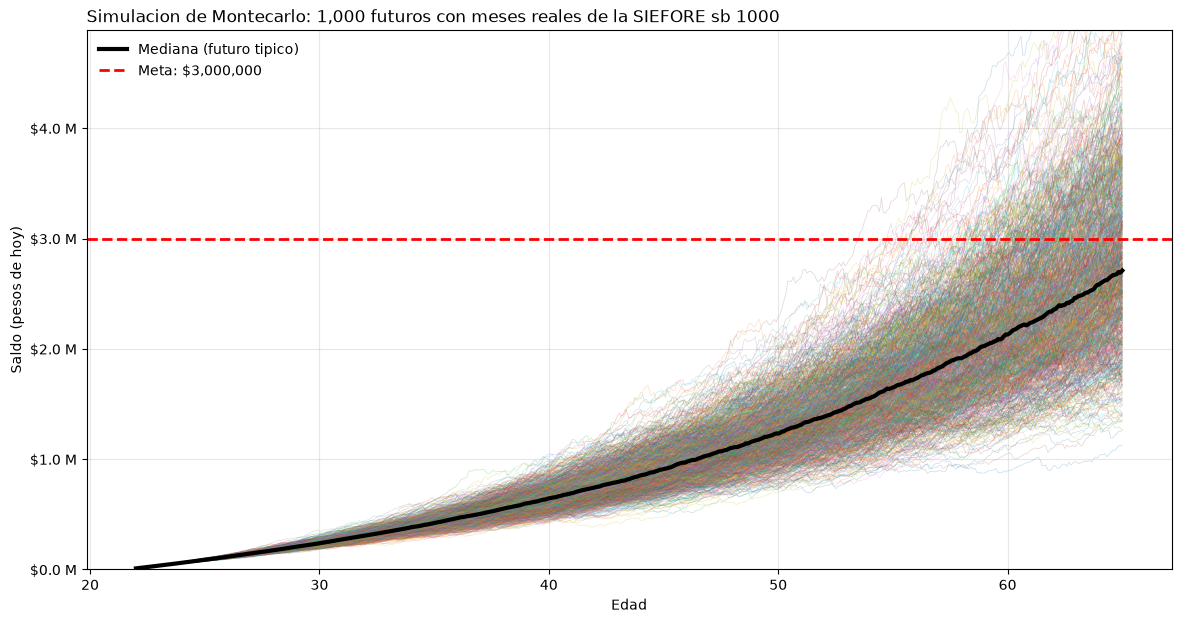

In [61]:
# Graficamos todos los futuros
# eje x en edad: cada mes es 1/12 de año
edades = EDAD_ACTUAL + np.arange(meses + 1) / 12

plt.figure(figsize=(14, 7))
plt.plot(edades, Simulaciones, linewidth=0.5, alpha=0.25)      # cada columna = una linea = un futuro
# mediana de cada mes entre todos los futuros (axis=1) = el futuro tipico
plt.plot(edades, np.median(Simulaciones, axis=1), color='black', linewidth=3, label='Mediana (futuro tipico)')
plt.axhline(META, color='red', linestyle='--', linewidth=2, label=f'Meta: ${META:,.0f}')
plt.ylim(0, np.percentile(finales, 99))                        # se corta el 1% mas alto para que se lea mejor
# eje y en millones, ej. 2500000 -> $2.5 M
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x / 1e6:,.1f} M'))
plt.title(f'Simulacion de Montecarlo: {trials:,} futuros con meses reales de la SIEFORE {SIEFORE}', loc='left')
plt.ylabel('Saldo (pesos de hoy)')
plt.xlabel('Edad')
plt.legend(loc='upper left', frameon=False)
plt.grid(alpha=0.3)
plt.show()

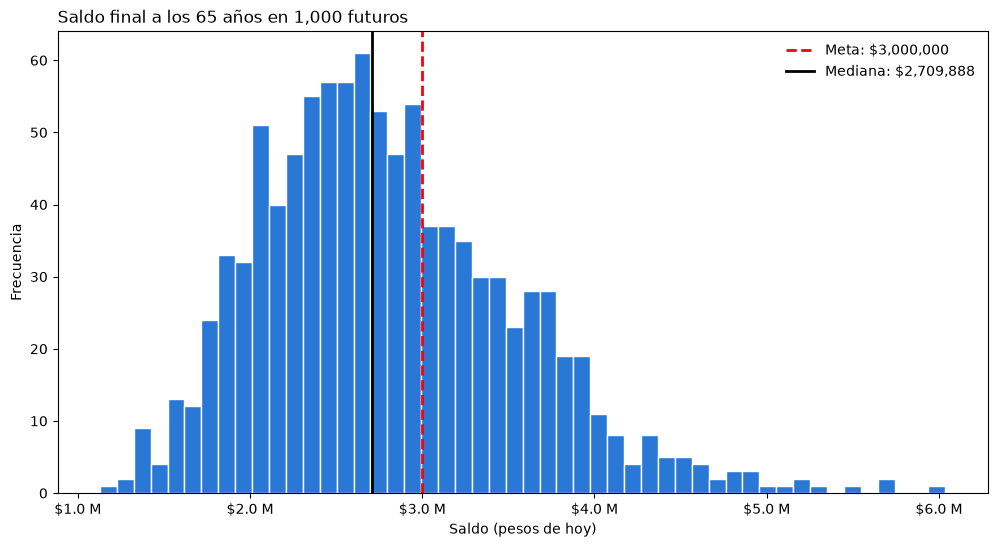

In [62]:
#Histograma del saldo final: cuantos futuros terminaron en cada rango de dinero
plt.figure(figsize=(12, 6))
plt.hist(finales, bins=50, color='#2a78d6', edgecolor='white')
plt.axvline(META, color='red', linestyle='--', linewidth=2, label=f'Meta: ${META:,.0f}')
plt.axvline(np.median(finales), color='black', linewidth=2, label=f'Mediana: ${np.median(finales):,.0f}')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x / 1e6:,.1f} M'))
plt.title(f'Saldo final a los {EDAD_RETIRO} años en {trials:,} futuros', loc='left')
plt.xlabel('Saldo (pesos de hoy)')
plt.ylabel('Frecuencia')
plt.legend(frameon=False)
plt.show()

### 8. Referencias

- *Método de Montecarlo*. https://es.wikipedia.org/wiki/M%C3%A9todo_de_Montecarlo
- *Precios de bolsa de las SIEFORE*. https://www.datos.gob.mx/dataset/precios_bolsa_siefore
- *Rendimientos de las AFORE*. https://www.datos.gob.mx/dataset/rendimientos_afore
- *Índice Nacional de Precios al Consumidor*. https://calcu.mx/inpc/historico